<a href="https://colab.research.google.com/github/tousif47/Geostormcaster/blob/main/02_model_a_t3h.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Model A: t+3h storm forecast, physics-informed features

Task: detect storms (Kp >= 6) in the next 3-hour block.
Inputs: 24h windows of 6 physics-informed solar wind features.
Formulation: binary (storm vs. non-storm), sigmoid output, threshold swept on validation.

Selection metric: storm F1 on validation. Test set used once, at the end.

In [1]:
import numpy as np
import json
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, f1_score

tf.keras.utils.set_random_seed(42)

OUT_DIR = '/content/drive/MyDrive/temp'
CSV     = f'{OUT_DIR}/omni_clean.csv'

D = np.load(f'{OUT_DIR}/windows_a.npz')
XA = {k: D[k] for k in D.files}
print({k: v.shape for k, v in XA.items()})

yb_tr = (XA['ytr'] == 2).astype(np.float32)
yb_va = (XA['yva'] == 2).astype(np.float32)
CLASS_WEIGHT = {0: 1.0, 1: 8.0}

{'Xtr': (240312, 24, 6), 'Xva': (69349, 24, 6), 'Xte': (65960, 24, 6), 'ytr': (240312,), 'yva': (69349,), 'yte': (65960,), 'ttr': (240312,), 'tva': (69349,), 'tte': (65960,)}


## Baselines (validation)

Climatology: always predict non-storm (the accuracy trap, made concrete).
Persistence: predict the current block's class ("next = same") — the standard
skill bar in Kp-forecasting literature.

In [2]:
df = pd.read_csv(CSV, parse_dates=['timestamp']).set_index('timestamp')

def eval_bin(y_true, y_pred, name):
    print(f'--- {name} ---')
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print(classification_report(y_true, y_pred,
          target_names=['non-storm', 'storm'], digits=3, zero_division=0))
    return f1_score(y_true, y_pred)

f1_climo = eval_bin(yb_va, np.zeros_like(yb_va), 'Climatology (always non-storm)')

cur_kp = df['kp'].reindex(XA['tva']).clip(upper=9).values
f1_persist = eval_bin(yb_va, (cur_kp >= 6).astype(int), 'Persistence')

--- Climatology (always non-storm) ---
[[68338     0]
 [ 1011     0]]
              precision    recall  f1-score   support

   non-storm      0.985     1.000     0.993     68338
       storm      0.000     0.000     0.000      1011

    accuracy                          0.985     69349
   macro avg      0.493     0.500     0.496     69349
weighted avg      0.971     0.985     0.978     69349

--- Persistence ---
[[68215   123]
 [  753   258]]
              precision    recall  f1-score   support

   non-storm      0.989     0.998     0.994     68338
       storm      0.677     0.255     0.371      1011

    accuracy                          0.987     69349
   macro avg      0.833     0.627     0.682     69349
weighted avg      0.985     0.987     0.985     69349



## Candidates

Three architectures, identical recipe (same optimizer, loss, batch size,
early stopping, class weights). Only the architecture differs.

1. MLP on window statistics (mean/std/min per feature over the 24h window)
2. 1D-CNN on the raw window
3. GRU on the raw window

In [3]:
def window_stats(X):
    return np.concatenate([X.mean(axis=1), X.std(axis=1), X.min(axis=1)], axis=1)

S = {k: (window_stats(v) if k.startswith('X') else v) for k, v in XA.items()}

def make_mlp():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(18,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def make_cnn():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(24, 6)),
        tf.keras.layers.Conv1D(32, 3, activation='relu'),
        tf.keras.layers.Conv1D(64, 3, activation='relu'),
        tf.keras.layers.GlobalAveragePooling1D(),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def make_gru():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(24, 6)),
        tf.keras.layers.GRU(16),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def train_bin(make_model, Xtr, Xva, tag, epochs=40, patience=6):
    m = make_model()
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    m.fit(Xtr, yb_tr,
          validation_data=(Xva, yb_va),
          epochs=epochs, batch_size=512, class_weight=CLASS_WEIGHT,
          callbacks=[tf.keras.callbacks.EarlyStopping(
              patience=patience, restore_best_weights=True)],
          verbose=1)
    m.save(f'{OUT_DIR}/model_{tag}.keras')
    return m

## Training

All three candidates train with an identical recipe: same optimizer, loss,
batch size, epoch cap, early stopping, and class weights. Only the
architecture differs, which keeps the comparison that follows clean.

Expected runtime: a few minutes total in Colab. The GRU is the slowest;
if a cell seems to pause near the end of an epoch, it is the early-stopping
check, not a hang.

In [4]:
m_mlp = train_bin(make_mlp, S['Xtr'], S['Xva'], 'a_mlp')
m_cnn = train_bin(make_cnn, XA['Xtr'], XA['Xva'], 'a_cnn')
m_gru = train_bin(make_gru, XA['Xtr'], XA['Xva'], 'a_gru')
candidates = {'MLP': (m_mlp, S['Xva']), '1D-CNN': (m_cnn, XA['Xva']), 'GRU': (m_gru, XA['Xva'])}

Epoch 1/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9146 - loss: 0.4066 - val_accuracy: 0.9476 - val_loss: 0.1269
Epoch 2/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9264 - loss: 0.3522 - val_accuracy: 0.9540 - val_loss: 0.1207
Epoch 3/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9288 - loss: 0.3438 - val_accuracy: 0.9515 - val_loss: 0.1248
Epoch 4/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9296 - loss: 0.3401 - val_accuracy: 0.9527 - val_loss: 0.1251
Epoch 5/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9308 - loss: 0.3375 - val_accuracy: 0.9546 - val_loss: 0.1225
Epoch 6/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9311 - loss: 0.3352 - val_accuracy: 0.9556 - val_loss: 0.1204
Epoch 7/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9315 - loss: 0.3345 - val_accuracy: 0.9551 - val_loss: 0.1230
Epoch 8/40
470/470 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9321 - loss: 0.3324 - val_accuracy: 0.

## Threshold sweep (validation)

Predict storm when P(storm) > tau, sweep tau. tau is chosen on validation
and becomes a fixed constant of the deployed model, like the normalization stats.

MLP      best tau=0.67  val storm F1=0.320
1D-CNN   best tau=0.71  val storm F1=0.406
GRU      best tau=0.75  val storm F1=0.451


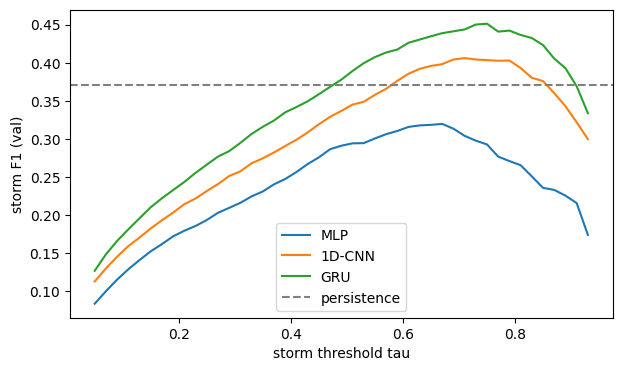

In [5]:
taus = np.arange(0.05, 0.95, 0.02)
swept = {}
plt.figure(figsize=(7, 4))

for name, (m, Xv) in candidates.items():
    p = m.predict(Xv, verbose=0).squeeze()
    f1s = [f1_score(yb_va, (p > t).astype(int)) for t in taus]
    best = int(np.argmax(f1s))
    swept[name] = (float(taus[best]), float(f1s[best]))
    print(f'{name:8s} best tau={taus[best]:.2f}  val storm F1={f1s[best]:.3f}')
    plt.plot(taus, f1s, label=name)

plt.axhline(f1_persist, color='gray', linestyle='--', label='persistence')
plt.xlabel('storm threshold tau'); plt.ylabel('storm F1 (val)')
plt.legend(); plt.show()

## Winner → test set, once

The model with the highest storm F1 on validation (including its tuned
threshold tau) is evaluated below on the test split — data from 2019 onward
that no training or selection decision has seen. This is the single point
where the test set is used, which keeps the final numbers unbiased.

The cell prints the test confusion matrix and precision/recall/F1 for both
classes, then places the model side-by-side with the persistence baseline
on the same split — the comparison that decides whether the model carries
genuine forecasting skill. Everything (winner, tau, all F1 scores, full
classification report) is written to model_a_results.json for the
firmware step and final summary.

In [ ]:
winner_name = max(swept, key=lambda n: swept[n][1])
best_tau, best_f1 = swept[winner_name]
print(f'winner: {winner_name} (tau={best_tau:.2f}, val storm F1={best_f1:.3f})')

w_model = candidates[winner_name][0]
if winner_name == 'MLP':
    w_Xte = S['Xte']
else:
    w_Xte = XA['Xte']

p_te = w_model.predict(w_Xte, verbose=0).squeeze()
pred_te = (p_te > best_tau).astype(int)
yb_te = (XA['yte'] == 2).astype(int)
f1_test = eval_bin(yb_te, pred_te, f'{winner_name} (tau={best_tau:.2f}) on TEST')

cur_kp_te = df['kp'].reindex(XA['tte']).clip(upper=9).values
f1_persist_te = eval_bin(yb_te, (cur_kp_te >= 6).astype(int), 'Persistence on TEST')

print('\n===== FINAL COMPARISON (test split) =====')
print(f'{winner_name} (tau={best_tau:.2f})  storm F1 = {f1_test:.3f}')
print(f'Persistence                  storm F1 = {f1_persist_te:.3f}')

summary = {
    'task': 'model_a_t3h_storm_binary',
    'features': ['bz_gsm', 'speed', 'density', 'newell', 'rect_v', 'pressure'],
    'winner': winner_name,
    'best_tau': best_tau,
    'val_storm_f1': {n: v[1] for n, v in swept.items()},
    'val_storm_f1_baselines': {'climatology': float(f1_climo), 'persistence': float(f1_persist)},
    'test_storm_f1': float(f1_test),
    'test_storm_f1_persistence': float(f1_persist_te),
    'test_report': classification_report(yb_te, pred_te,
                      target_names=['non-storm', 'storm'], output_dict=True),
}
with open(f'{OUT_DIR}/model_a_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('saved model_a_results.json')

winner: GRU (tau=0.75, val storm F1=0.451)
--- GRU (tau=0.75) on TEST ---
[[64060   844]
 [  424   632]]
              precision    recall  f1-score   support

   non-storm      0.993     0.987     0.990     64904
       storm      0.428     0.598     0.499      1056

    accuracy                          0.981     65960
   macro avg      0.711     0.793     0.745     65960
weighted avg      0.984     0.981     0.982     65960

--- Persistence on TEST ---
[[64757   147]
 [  697   359]]
              precision    recall  f1-score   support

   non-storm      0.989     0.998     0.994     64904
       storm      0.709     0.340     0.460      1056

    accuracy                          0.987     65960
   macro avg      0.849     0.669     0.727     65960
weighted avg      0.985     0.987     0.985     65960


===== FINAL COMPARISON (test split) =====
GRU (tau=0.75)  storm F1 = 0.499
Persistence                  storm F1 = 0.460
saved model_a_results.json
